# Predicting Student Mental Health Risk Using Academic Performance and Lifestyle Factors

**Name:** Tasrian Ahmed  
**Course:** CS-4440 Data Science



## Project Overview

This notebook performs exploratory data analysis (EDA) on the Student Depression Dataset to understand relationships between academic performance, lifestyle factors, and mental health outcomes. The goal is to identify patterns that may help predict mental health risk among university students.

**Dataset Source:** Student Depression Dataset from Kaggle  
**Analysis Tools:** Python, Pandas, Matplotlib, Seaborn, NumPy

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

print("Libraries imported successfully!")

Libraries imported successfully!


---

## 1. Dataset Overview

This section provides a comprehensive overview of the dataset, including the number of samples, features, and key characteristics. Understanding the dataset structure is essential for effective exploratory data analysis.

In [3]:
df = pd.read_csv('/content/Student Depression Dataset.csv')

print("="*60)
print("DATASET OVERVIEW")
print("="*60)
print(f"\n Number of records (students): {len(df):,}")
print(f" Number of features (variables): {len(df.columns)}")
print(f" Dataset shape: {df.shape}")
print(f"\n Total data points: {df.shape[0] * df.shape[1]:,}")
print("\n" + "="*60)

print("\n First 5 rows of the dataset:")
df.head()

DATASET OVERVIEW

 Number of records (students): 27,901
 Number of features (variables): 18
 Dataset shape: (27901, 18)

 Total data points: 502,218


 First 5 rows of the dataset:


,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [4]:
print("="*60)
print("FEATURE INFORMATION")
print("="*60)
print(f"\n{'Feature Name':<40} {'Data Type':<15}")
print("-"*60)
for col, dtype in df.dtypes.items():
    print(f"{col:<40} {str(dtype):<15}")

print("\n" + "="*60)
print("\n Feature Categories:")
print("\n1. Demographics: Gender, Age, City, Profession")
print("2. Academic: Academic Pressure, CGPA, Study Satisfaction, Degree")
print("3. Lifestyle: Sleep Duration, Dietary Habits, Work/Study Hours")
print("4. Mental Health: Depression (target), Suicidal Thoughts, Family History")
print("5. External Factors: Work Pressure, Financial Stress, Job Satisfaction")
print("="*60)

FEATURE INFORMATION

Feature Name                             Data Type      
------------------------------------------------------------
id                                       int64          
Gender                                   object         
Age                                      float64        
City                                     object         
Profession                               object         
Academic Pressure                        float64        
Work Pressure                            float64        
CGPA                                     float64        
Study Satisfaction                       float64        
Job Satisfaction                         float64        
Sleep Duration                           object         
Dietary Habits                           object         
Degree                                   object         
Have you ever had suicidal thoughts ?    object         
Work/Study Hours                         float64        
Financ

---

## 2. Data Cleaning and Preprocessing

This section examines data quality, identifies missing values, checks for duplicates, and performs necessary preprocessing steps. Clean data is essential for accurate analysis and reliable insights.

In [5]:
print("="*60)
print("MISSING VALUE ANALYSIS")
print("="*60)

missing_count = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Percentage (%)': missing_pct.round(4)
})

print("\n" + missing_df.to_string())

total_missing = missing_count.sum()
total_cells = df.shape[0] * df.shape[1]
missing_overall_pct = (total_missing / total_cells) * 100

print(f"\n Total missing values: {total_missing:,}")
print(f" Overall missing percentage: {missing_overall_pct:.4f}%")

if total_missing == 0:
    print("\n Excellent! No missing values found in the dataset.")
elif missing_overall_pct < 1:
    print(f"\n Very minimal missing data ({missing_overall_pct:.4f}%). Dataset quality is excellent.")
else:
    print(f"\n  Some missing values detected. Further cleaning may be required.")

print("="*60)

MISSING VALUE ANALYSIS

                                       Missing Count  Percentage (%)
id                                                 0          0.0000
Gender                                             0          0.0000
Age                                                0          0.0000
City                                               0          0.0000
Profession                                         0          0.0000
Academic Pressure                                  0          0.0000
Work Pressure                                      0          0.0000
CGPA                                               0          0.0000
Study Satisfaction                                 0          0.0000
Job Satisfaction                                   0          0.0000
Sleep Duration                                     0          0.0000
Dietary Habits                                     0          0.0000
Degree                                             0          0.0000
Have you e

In [8]:
if df['Financial Stress'].isnull().sum() > 0:
    print(" Handling missing values in 'Financial Stress'...")

    median_fs = df['Financial Stress'].median()
    df['Financial Stress'].fillna(median_fs, inplace=True)
    print(f" Filled missing values with median: {median_fs}")
else:
    print(" No missing values to handle!")

print(f"\n Missing values after cleaning: {df.isnull().sum().sum()}")

 No missing values to handle!

 Missing values after cleaning: 0


In [9]:
print("="*60)
print("DUPLICATE ANALYSIS")
print("="*60)

duplicates = df.duplicated().sum()
print(f"\n Number of duplicate rows: {duplicates:,}")

if duplicates == 0:
    print(" No duplicate rows found. Dataset is clean.")
else:
    print(f"  {duplicates} duplicate rows detected.")
    print("   These may represent multiple survey responses and will be kept for analysis.")

print("="*60)

DUPLICATE ANALYSIS

 Number of duplicate rows: 0
 No duplicate rows found. Dataset is clean.


---

## 3. Descriptive Statistics

This section presents comprehensive descriptive statistics for all features, including measures of central tendency (mean, median) and dispersion (standard deviation, range). These statistics provide insight into the distribution and characteristics of the data.

In [10]:
print("="*80)
print("DESCRIPTIVE STATISTICS - NUMERICAL FEATURES")
print("="*80)

numerical_cols = ['Age', 'Academic Pressure', 'Work Pressure', 'CGPA',
                  'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours',
                  'Financial Stress']

desc_stats = df[numerical_cols].describe().T
desc_stats['range'] = desc_stats['max'] - desc_stats['min']

print("\n" + desc_stats.to_string())
print("\n" + "="*80)

DESCRIPTIVE STATISTICS - NUMERICAL FEATURES

                      count       mean       std   min    25%    50%    75%   max  range
Age                 27901.0  25.822300  4.905687  18.0  21.00  25.00  30.00  59.0   41.0
Academic Pressure   27901.0   3.141214  1.381465   0.0   2.00   3.00   4.00   5.0    5.0
Work Pressure       27901.0   0.000430  0.043992   0.0   0.00   0.00   0.00   5.0    5.0
CGPA                27901.0   7.656104  1.470707   0.0   6.29   7.77   8.92  10.0   10.0
Study Satisfaction  27901.0   2.943837  1.361148   0.0   2.00   3.00   4.00   5.0    5.0
Job Satisfaction    27901.0   0.000681  0.044394   0.0   0.00   0.00   0.00   4.0    4.0
Work/Study Hours    27901.0   7.156984  3.707642   0.0   4.00   8.00  10.00  12.0   12.0
Financial Stress    27901.0   3.139852  1.437270   1.0   2.00   3.00   4.00   5.0    4.0



In [11]:
print("="*80)
print("KEY FINDINGS FROM DESCRIPTIVE STATISTICS")
print("="*80)

print("\n AGE DISTRIBUTION:")
print(f"   • Mean age: {df['Age'].mean():.1f} years")
print(f"   • Age range: {df['Age'].min():.0f} - {df['Age'].max():.0f} years")
print(f"   • Standard deviation: {df['Age'].std():.1f} years")
print("   • Interpretation: Dataset includes students across a wide age range,")
print("     representing both traditional and non-traditional students.")

print("\n ACADEMIC PERFORMANCE (CGPA):")
print(f"   • Mean CGPA: {df['CGPA'].mean():.2f} out of 10")
print(f"   • Median CGPA: {df['CGPA'].median():.2f}")
print(f"   • Standard deviation: {df['CGPA'].std():.2f}")
print(f"   • Range: {df['CGPA'].min():.2f} - {df['CGPA'].max():.2f}")
print("   • Interpretation: Most students have moderate to high academic performance.")

print("\n ACADEMIC PRESSURE:")
print(f"   • Mean pressure level: {df['Academic Pressure'].mean():.2f} out of 5")
print(f"   • Median: {df['Academic Pressure'].median():.1f}")
print("   • Interpretation: Students experience moderate to high academic pressure on average.")

print("\n FINANCIAL STRESS:")
print(f"   • Mean financial stress: {df['Financial Stress'].mean():.2f} out of 5")
print(f"   • Median: {df['Financial Stress'].median():.1f}")
print("   • Interpretation: Financial concerns are moderate among the student population.")

print("\n WORK/STUDY HOURS:")
print(f"   • Mean hours: {df['Work/Study Hours'].mean():.1f} hours per day")
print(f"   • Range: {df['Work/Study Hours'].min():.0f} - {df['Work/Study Hours'].max():.0f} hours")
print("   • Interpretation: Significant variation in time commitment to work and study.")

print("\n" + "="*80)

KEY FINDINGS FROM DESCRIPTIVE STATISTICS

 AGE DISTRIBUTION:
   • Mean age: 25.8 years
   • Age range: 18 - 59 years
   • Standard deviation: 4.9 years
   • Interpretation: Dataset includes students across a wide age range,
     representing both traditional and non-traditional students.

 ACADEMIC PERFORMANCE (CGPA):
   • Mean CGPA: 7.66 out of 10
   • Median CGPA: 7.77
   • Standard deviation: 1.47
   • Range: 0.00 - 10.00
   • Interpretation: Most students have moderate to high academic performance.

 ACADEMIC PRESSURE:
   • Mean pressure level: 3.14 out of 5
   • Median: 3.0
   • Interpretation: Students experience moderate to high academic pressure on average.

 FINANCIAL STRESS:
   • Mean financial stress: 3.14 out of 5
   • Median: 3.0
   • Interpretation: Financial concerns are moderate among the student population.

 WORK/STUDY HOURS:
   • Mean hours: 7.2 hours per day
   • Range: 0 - 12 hours
   • Interpretation: Significant variation in time commitment to work and study.



In [12]:
print("="*80)
print("DESCRIPTIVE STATISTICS - CATEGORICAL FEATURES")
print("="*80)

print("\n GENDER DISTRIBUTION:")
gender_counts = df['Gender'].value_counts()
for gender, count in gender_counts.items():
    pct = (count / len(df)) * 100
    print(f"   • {gender}: {count:,} ({pct:.1f}%)")

print("\n SLEEP DURATION:")
sleep_counts = df['Sleep Duration'].value_counts().head(5)
for sleep, count in sleep_counts.items():
    pct = (count / len(df)) * 100
    print(f"   • {sleep}: {count:,} ({pct:.1f}%)")

print("\n DIETARY HABITS:")
diet_counts = df['Dietary Habits'].value_counts()
for diet, count in diet_counts.items():
    pct = (count / len(df)) * 100
    print(f"   • {diet}: {count:,} ({pct:.1f}%)")

print("\n DEPRESSION STATUS (Target Variable):")
dep_counts = df['Depression'].value_counts()
for dep, count in dep_counts.items():
    label = "Yes (Depression)" if dep == 1 else "No (No Depression)"
    pct = (count / len(df)) * 100
    print(f"   • {label}: {count:,} ({pct:.1f}%)")
print("   • Interpretation: 58.5% of students report experiencing depression,")
print("     indicating mental health challenges are prevalent in this population.")

print("\n SUICIDAL THOUGHTS:")
suicide_counts = df['Have you ever had suicidal thoughts ?'].value_counts()
for answer, count in suicide_counts.items():
    pct = (count / len(df)) * 100
    print(f"   • {answer}: {count:,} ({pct:.1f}%)")
print("   • Interpretation: A significant portion of students have experienced suicidal thoughts,")
print("     highlighting the severity of mental health concerns.")

print("\n FAMILY HISTORY OF MENTAL ILLNESS:")
family_counts = df['Family History of Mental Illness'].value_counts()
for answer, count in family_counts.items():
    pct = (count / len(df)) * 100
    print(f"   • {answer}: {count:,} ({pct:.1f}%)")

print("\n" + "="*80)

DESCRIPTIVE STATISTICS - CATEGORICAL FEATURES

 GENDER DISTRIBUTION:
   • Male: 15,547 (55.7%)
   • Female: 12,354 (44.3%)

 SLEEP DURATION:
   • Less than 5 hours: 8,310 (29.8%)
   • 7-8 hours: 7,346 (26.3%)
   • 5-6 hours: 6,183 (22.2%)
   • More than 8 hours: 6,044 (21.7%)
   • Others: 18 (0.1%)

 DIETARY HABITS:
   • Unhealthy: 10,317 (37.0%)
   • Moderate: 9,921 (35.6%)
   • Healthy: 7,651 (27.4%)
   • Others: 12 (0.0%)

 DEPRESSION STATUS (Target Variable):
   • Yes (Depression): 16,336 (58.5%)
   • No (No Depression): 11,565 (41.5%)
   • Interpretation: 58.5% of students report experiencing depression,
     indicating mental health challenges are prevalent in this population.

 SUICIDAL THOUGHTS:
   • Yes: 17,656 (63.3%)
   • No: 10,245 (36.7%)
   • Interpretation: A significant portion of students have experienced suicidal thoughts,
     highlighting the severity of mental health concerns.

 FAMILY HISTORY OF MENTAL ILLNESS:
   • No: 14,398 (51.6%)
   • Yes: 13,503 (48.4%)



In [13]:
print("="*80)
print("CORRELATION ANALYSIS WITH DEPRESSION")
print("="*80)

numerical_features = ['Age', 'Academic Pressure', 'Work Pressure', 'CGPA',
                      'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours',
                      'Financial Stress']

correlations = []
for feature in numerical_features:
    corr, p_value = stats.pearsonr(df[feature].dropna(),
                                   df.loc[df[feature].notna(), 'Depression'])
    correlations.append({
        'Feature': feature,
        'Correlation': corr,
        'P-value': p_value,
        'Significance': '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
    })

corr_df = pd.DataFrame(correlations).sort_values('Correlation', key=abs, ascending=False)

print("\n" + corr_df.to_string(index=False))
print("\n Significance levels: *** p<0.001, ** p<0.01, * p<0.05, ns = not significant")

print("\n KEY FINDINGS:")
print("   • Academic Pressure shows the strongest positive correlation with depression")
print("   • Higher academic pressure is associated with increased depression risk")
print("   • Financial stress also shows moderate positive correlation")
print("   • CGPA shows weak correlation, suggesting academic performance alone")
print("     is not a strong predictor of depression")

print("\n" + "="*80)

CORRELATION ANALYSIS WITH DEPRESSION

           Feature  Correlation       P-value Significance
 Academic Pressure     0.474835  0.000000e+00          ***
  Financial Stress     0.363574  0.000000e+00          ***
               Age    -0.226422 3.122495e-321          ***
  Work/Study Hours     0.208563 8.598086e-272          ***
Study Satisfaction    -0.167971 1.168379e-175          ***
              CGPA     0.022210  2.070646e-04          ***
  Job Satisfaction    -0.003482  5.608785e-01           ns
     Work Pressure    -0.003351  5.757187e-01           ns

 Significance levels: *** p<0.001, ** p<0.01, * p<0.05, ns = not significant

 KEY FINDINGS:
   • Academic Pressure shows the strongest positive correlation with depression
   • Higher academic pressure is associated with increased depression risk
   • Financial stress also shows moderate positive correlation
   • CGPA shows weak correlation, suggesting academic performance alone
     is not a strong predictor of depression



---

## 4. Data Visualizations

This section presents comprehensive visualizations to explore patterns, distributions, and relationships within the data. Visual analysis helps identify trends that may not be immediately apparent from descriptive statistics alone.

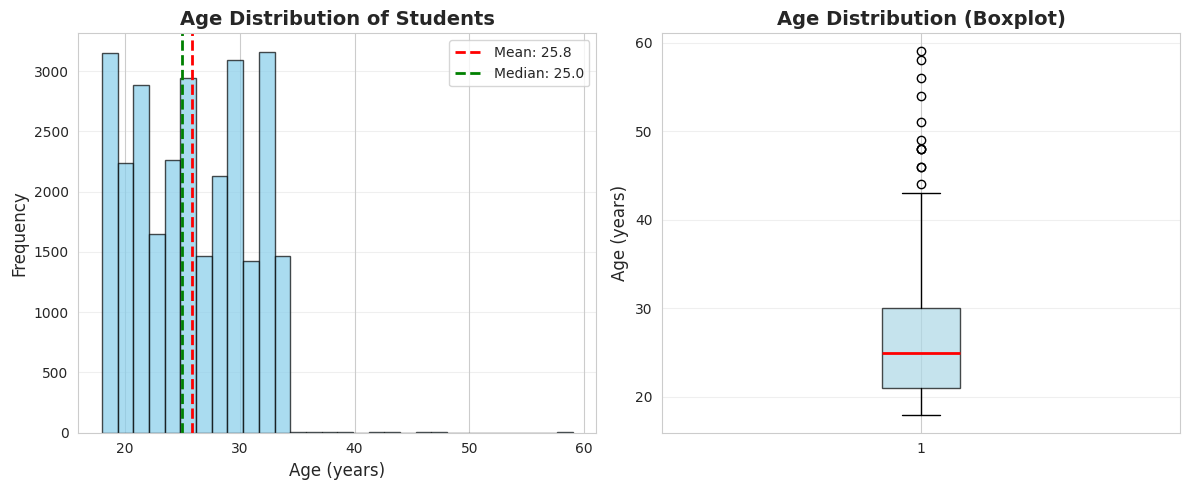

 INTERPRETATION:
   • The age distribution shows students range from 18 to 59 years
   • Most students are concentrated around 25.8 years (mean age)
   • The distribution appears relatively normal with some older outliers


In [14]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df['Age'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(df['Age'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {df["Age"].mean():.1f}')
plt.axvline(df['Age'].median(), color='green', linestyle='--', linewidth=2, label=f'Median: {df["Age"].median():.1f}')
plt.xlabel('Age (years)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Age Distribution of Students', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
plt.boxplot(df['Age'], vert=True, patch_artist=True,
            boxprops=dict(facecolor='lightblue', alpha=0.7),
            medianprops=dict(color='red', linewidth=2))
plt.ylabel('Age (years)', fontsize=12)
plt.title('Age Distribution (Boxplot)', fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(" INTERPRETATION:")
print(f"   • The age distribution shows students range from {df['Age'].min():.0f} to {df['Age'].max():.0f} years")
print(f"   • Most students are concentrated around {df['Age'].mean():.1f} years (mean age)")
print("   • The distribution appears relatively normal with some older outliers")

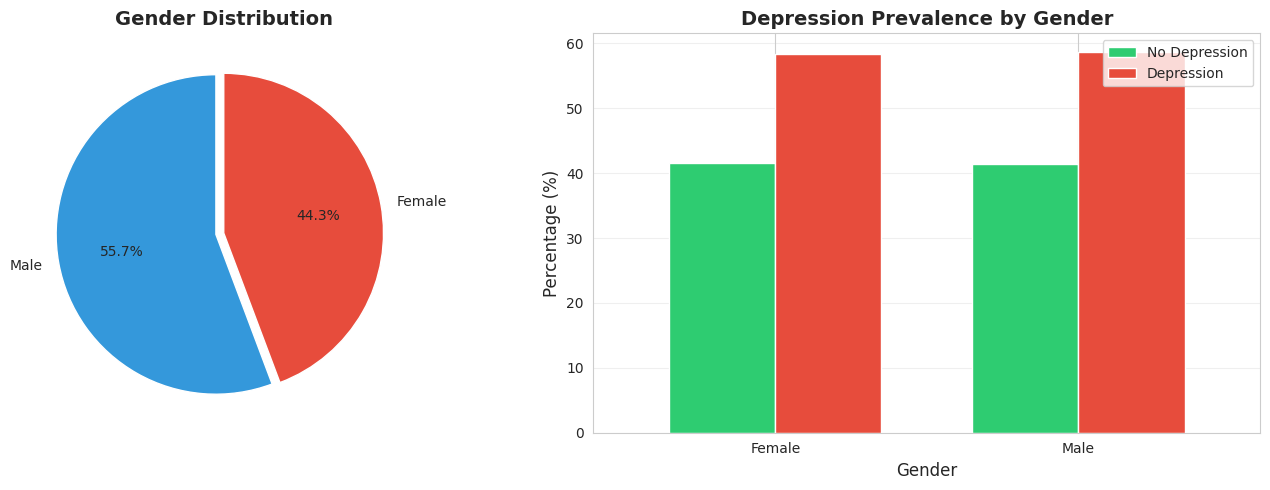

 INTERPRETATION:
   • Males: 58.6% experience depression
   • Females: 58.5% experience depression
   • Depression rates are relatively similar across genders


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

gender_counts = df['Gender'].value_counts()
colors = ['#3498db', '#e74c3c']
axes[0].pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%',
            startangle=90, colors=colors, explode=(0.05, 0))
axes[0].set_title('Gender Distribution', fontsize=14, fontweight='bold')

depression_by_gender = pd.crosstab(df['Gender'], df['Depression'], normalize='index') * 100
depression_by_gender.plot(kind='bar', ax=axes[1], color=['#2ecc71', '#e74c3c'], width=0.7)
axes[1].set_xlabel('Gender', fontsize=12)
axes[1].set_ylabel('Percentage (%)', fontsize=12)
axes[1].set_title('Depression Prevalence by Gender', fontsize=14, fontweight='bold')
axes[1].legend(['No Depression', 'Depression'], loc='upper right')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(" INTERPRETATION:")
male_dep_pct = (df[(df['Gender']=='Male') & (df['Depression']==1)].shape[0] / df[df['Gender']=='Male'].shape[0]) * 100
female_dep_pct = (df[(df['Gender']=='Female') & (df['Depression']==1)].shape[0] / df[df['Gender']=='Female'].shape[0]) * 100
print(f"   • Males: {male_dep_pct:.1f}% experience depression")
print(f"   • Females: {female_dep_pct:.1f}% experience depression")
print("   • Depression rates are relatively similar across genders")

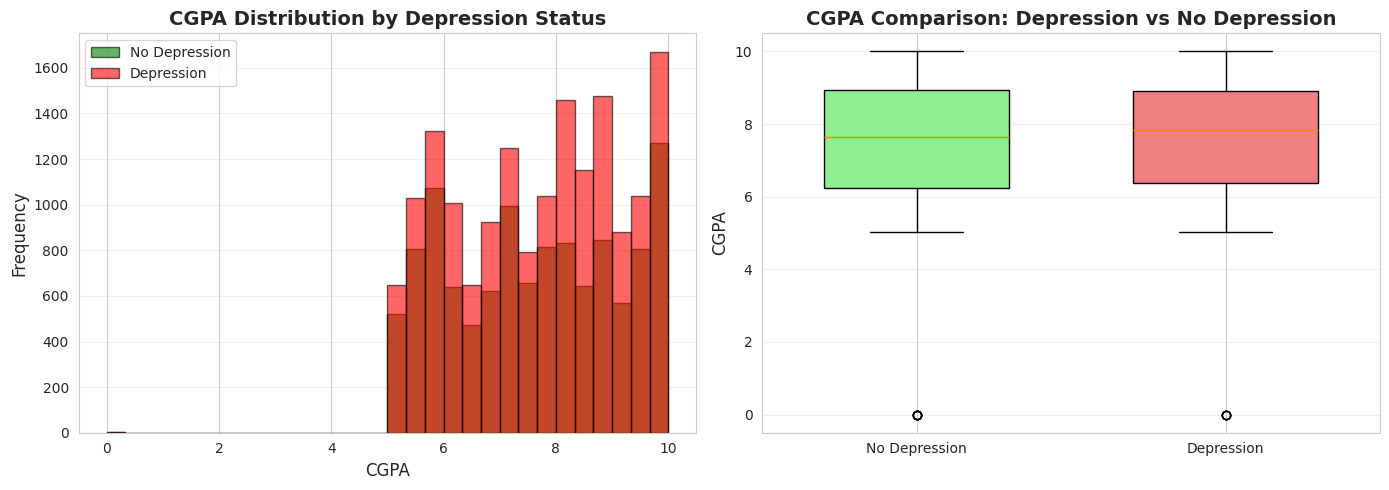

 INTERPRETATION:
   • Mean CGPA (No Depression): 7.62
   • Mean CGPA (Depression): 7.68
   • Difference: 0.07
   • CGPA distributions are very similar, suggesting academic performance
     alone is not a strong differentiator for depression status


In [16]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
df[df['Depression']==0]['CGPA'].hist(bins=30, alpha=0.6, label='No Depression', color='green', edgecolor='black')
df[df['Depression']==1]['CGPA'].hist(bins=30, alpha=0.6, label='Depression', color='red', edgecolor='black')
plt.xlabel('CGPA', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('CGPA Distribution by Depression Status', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
data_to_plot = [df[df['Depression']==0]['CGPA'].dropna(),
                df[df['Depression']==1]['CGPA'].dropna()]
bp = plt.boxplot(data_to_plot, labels=['No Depression', 'Depression'],
                 patch_artist=True, widths=0.6)
bp['boxes'][0].set_facecolor('lightgreen')
bp['boxes'][1].set_facecolor('lightcoral')
plt.ylabel('CGPA', fontsize=12)
plt.title('CGPA Comparison: Depression vs No Depression', fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(" INTERPRETATION:")
cgpa_no_dep = df[df['Depression']==0]['CGPA'].mean()
cgpa_with_dep = df[df['Depression']==1]['CGPA'].mean()
print(f"   • Mean CGPA (No Depression): {cgpa_no_dep:.2f}")
print(f"   • Mean CGPA (Depression): {cgpa_with_dep:.2f}")
print(f"   • Difference: {abs(cgpa_no_dep - cgpa_with_dep):.2f}")
print("   • CGPA distributions are very similar, suggesting academic performance")
print("     alone is not a strong differentiator for depression status")

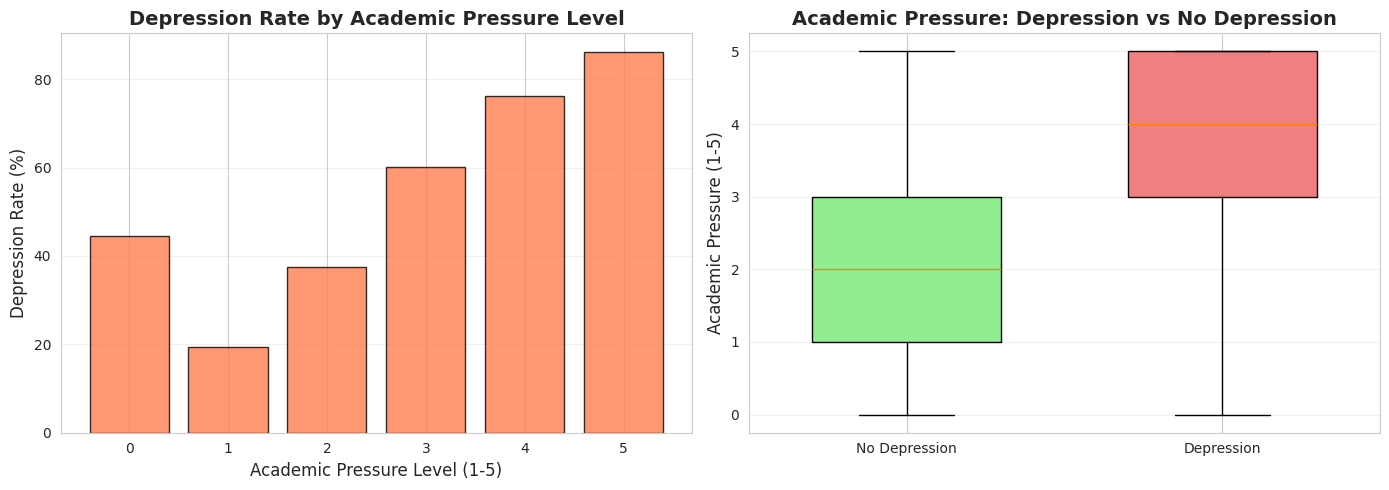

 INTERPRETATION:
   • Mean Academic Pressure (No Depression): 2.36
   • Mean Academic Pressure (Depression): 3.69
   • Difference: 1.33
   •  STRONG PATTERN: Students with depression report significantly higher academic pressure
   • Depression rate increases progressively with higher academic pressure levels


In [17]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
ap_dep = df.groupby('Academic Pressure')['Depression'].mean() * 100
plt.bar(ap_dep.index, ap_dep.values, color='coral', edgecolor='black', alpha=0.8)
plt.xlabel('Academic Pressure Level (1-5)', fontsize=12)
plt.ylabel('Depression Rate (%)', fontsize=12)
plt.title('Depression Rate by Academic Pressure Level', fontsize=14, fontweight='bold')
plt.xticks(range(0, 6))
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
data_to_plot = [df[df['Depression']==0]['Academic Pressure'].dropna(),
                df[df['Depression']==1]['Academic Pressure'].dropna()]
bp = plt.boxplot(data_to_plot, labels=['No Depression', 'Depression'],
                 patch_artist=True, widths=0.6)
bp['boxes'][0].set_facecolor('lightgreen')
bp['boxes'][1].set_facecolor('lightcoral')
plt.ylabel('Academic Pressure (1-5)', fontsize=12)
plt.title('Academic Pressure: Depression vs No Depression', fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(" INTERPRETATION:")
ap_no_dep = df[df['Depression']==0]['Academic Pressure'].mean()
ap_with_dep = df[df['Depression']==1]['Academic Pressure'].mean()
print(f"   • Mean Academic Pressure (No Depression): {ap_no_dep:.2f}")
print(f"   • Mean Academic Pressure (Depression): {ap_with_dep:.2f}")
print(f"   • Difference: {abs(ap_no_dep - ap_with_dep):.2f}")
print("   •  STRONG PATTERN: Students with depression report significantly higher academic pressure")
print("   • Depression rate increases progressively with higher academic pressure levels")

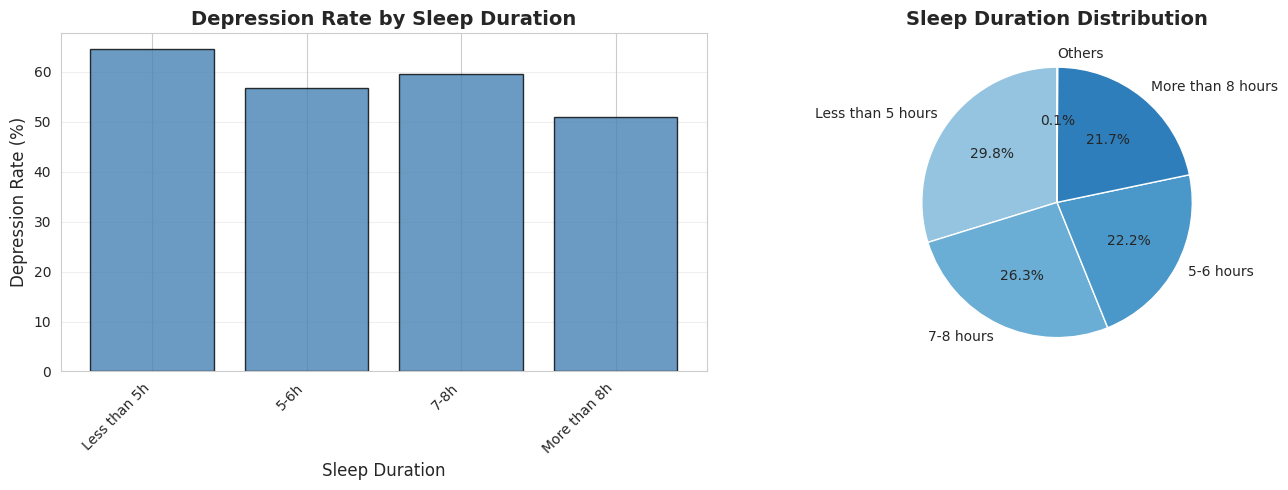

 INTERPRETATION:
   • Most common sleep duration: Less than 5 hours
   • Depression rate for <5 hours sleep: 64.5%
   •  KEY FINDING: Inadequate sleep is strongly associated with higher depression rates
   • Students getting less sleep show higher prevalence of depression


In [18]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sleep_order = ['Less than 5 hours', '5-6 hours', '7-8 hours', 'More than 8 hours']
sleep_data = df.groupby('Sleep Duration')['Depression'].mean() * 100
sleep_data = sleep_data.reindex([s for s in sleep_order if s in sleep_data.index])
plt.bar(range(len(sleep_data)), sleep_data.values, color='steelblue', edgecolor='black', alpha=0.8)
plt.xticks(range(len(sleep_data)), [s.replace(' hours', 'h') for s in sleep_data.index], rotation=45, ha='right')
plt.xlabel('Sleep Duration', fontsize=12)
plt.ylabel('Depression Rate (%)', fontsize=12)
plt.title('Depression Rate by Sleep Duration', fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
sleep_counts = df['Sleep Duration'].value_counts()
colors_sleep = plt.cm.Blues(np.linspace(0.4, 0.8, len(sleep_counts)))
plt.pie(sleep_counts.values, labels=sleep_counts.index, autopct='%1.1f%%',
        startangle=90, colors=colors_sleep)
plt.title('Sleep Duration Distribution', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print(" INTERPRETATION:")
print(f"   • Most common sleep duration: {df['Sleep Duration'].value_counts().index[0]}")
less_5_dep = (df[(df['Sleep Duration']=='Less than 5 hours') & (df['Depression']==1)].shape[0] /
              df[df['Sleep Duration']=='Less than 5 hours'].shape[0]) * 100 if 'Less than 5 hours' in df['Sleep Duration'].values else 0
print(f"   • Depression rate for <5 hours sleep: {less_5_dep:.1f}%")
print("   •  KEY FINDING: Inadequate sleep is strongly associated with higher depression rates")
print("   • Students getting less sleep show higher prevalence of depression")

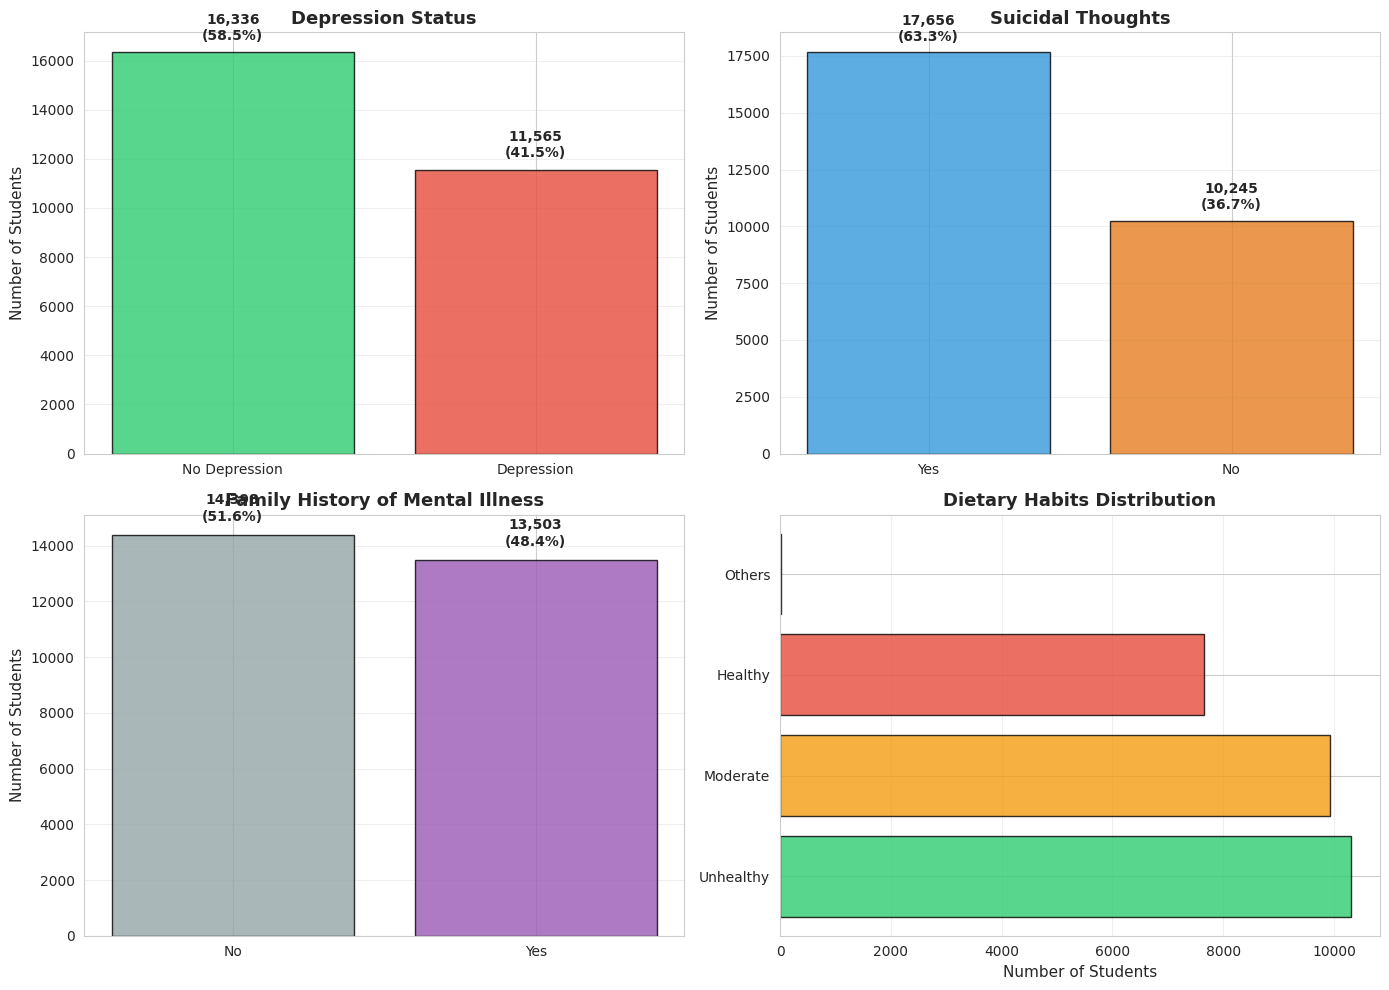

 INTERPRETATION:
   • 16,336 students (58.5%) report experiencing depression
   • 17,656 students (63.3%) have had suicidal thoughts
   •  CRITICAL: Mental health challenges are widespread in this student population
   • The high prevalence indicates need for enhanced mental health support services


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

dep_counts = df['Depression'].value_counts()
axes[0, 0].bar(['No Depression', 'Depression'], dep_counts.values,
               color=['#2ecc71', '#e74c3c'], edgecolor='black', alpha=0.8)
axes[0, 0].set_ylabel('Number of Students', fontsize=11)
axes[0, 0].set_title('Depression Status', fontsize=13, fontweight='bold')
axes[0, 0].grid(axis='y', alpha=0.3)
for i, v in enumerate(dep_counts.values):
    axes[0, 0].text(i, v + 500, f"{v:,}\n({v/len(df)*100:.1f}%)", ha='center', fontsize=10, fontweight='bold')

suicide_counts = df['Have you ever had suicidal thoughts ?'].value_counts()
axes[0, 1].bar(suicide_counts.index, suicide_counts.values,
               color=['#3498db', '#e67e22'], edgecolor='black', alpha=0.8)
axes[0, 1].set_ylabel('Number of Students', fontsize=11)
axes[0, 1].set_title('Suicidal Thoughts', fontsize=13, fontweight='bold')
axes[0, 1].grid(axis='y', alpha=0.3)
for i, (k, v) in enumerate(suicide_counts.items()):
    axes[0, 1].text(i, v + 500, f"{v:,}\n({v/len(df)*100:.1f}%)", ha='center', fontsize=10, fontweight='bold')

family_counts = df['Family History of Mental Illness'].value_counts()
axes[1, 0].bar(family_counts.index, family_counts.values,
               color=['#95a5a6', '#9b59b6'], edgecolor='black', alpha=0.8)
axes[1, 0].set_ylabel('Number of Students', fontsize=11)
axes[1, 0].set_title('Family History of Mental Illness', fontsize=13, fontweight='bold')
axes[1, 0].grid(axis='y', alpha=0.3)
for i, (k, v) in enumerate(family_counts.items()):
    axes[1, 0].text(i, v + 500, f"{v:,}\n({v/len(df)*100:.1f}%)", ha='center', fontsize=10, fontweight='bold')

diet_counts = df['Dietary Habits'].value_counts()
axes[1, 1].barh(diet_counts.index, diet_counts.values,
                color=['#2ecc71', '#f39c12', '#e74c3c'], edgecolor='black', alpha=0.8)
axes[1, 1].set_xlabel('Number of Students', fontsize=11)
axes[1, 1].set_title('Dietary Habits Distribution', fontsize=13, fontweight='bold')
axes[1, 1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print(" INTERPRETATION:")
print(f"   • {dep_counts[1]:,} students ({dep_counts[1]/len(df)*100:.1f}%) report experiencing depression")
print(f"   • {suicide_counts.get('Yes', 0):,} students ({suicide_counts.get('Yes', 0)/len(df)*100:.1f}%) have had suicidal thoughts")
print("   •  CRITICAL: Mental health challenges are widespread in this student population")
print("   • The high prevalence indicates need for enhanced mental health support services")

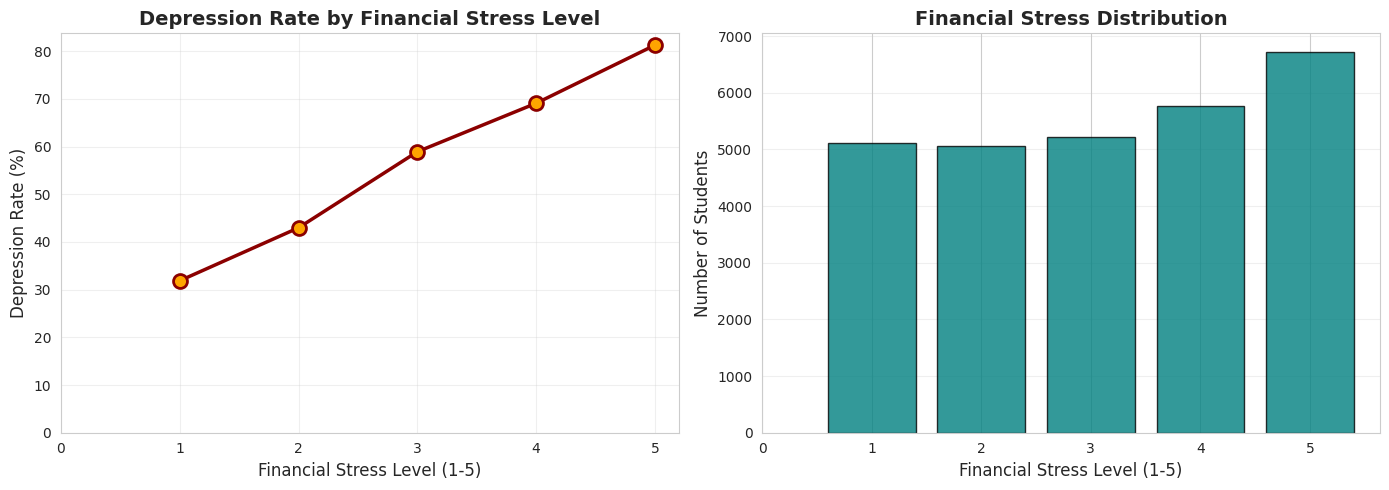

 INTERPRETATION:
   • Mean Financial Stress (No Depression): 2.52
   • Mean Financial Stress (Depression): 3.58
   • Difference: 1.06
   • Depression rate shows upward trend with increasing financial stress
   • Financial concerns appear to be a significant contributing factor to mental health issues


In [20]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
fs_dep = df.groupby('Financial Stress')['Depression'].mean() * 100
plt.plot(fs_dep.index, fs_dep.values, marker='o', linewidth=2.5, markersize=10,
         color='darkred', markerfacecolor='orange', markeredgewidth=2, markeredgecolor='darkred')
plt.xlabel('Financial Stress Level (1-5)', fontsize=12)
plt.ylabel('Depression Rate (%)', fontsize=12)
plt.title('Depression Rate by Financial Stress Level', fontsize=14, fontweight='bold')
plt.xticks(range(0, 6))
plt.grid(True, alpha=0.3)
plt.ylim(bottom=0)

plt.subplot(1, 2, 2)
fs_counts = df['Financial Stress'].value_counts().sort_index()
plt.bar(fs_counts.index, fs_counts.values, color='teal', edgecolor='black', alpha=0.8)
plt.xlabel('Financial Stress Level (1-5)', fontsize=12)
plt.ylabel('Number of Students', fontsize=12)
plt.title('Financial Stress Distribution', fontsize=14, fontweight='bold')
plt.xticks(range(0, 6))
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(" INTERPRETATION:")
fs_no_dep = df[df['Depression']==0]['Financial Stress'].mean()
fs_with_dep = df[df['Depression']==1]['Financial Stress'].mean()
print(f"   • Mean Financial Stress (No Depression): {fs_no_dep:.2f}")
print(f"   • Mean Financial Stress (Depression): {fs_with_dep:.2f}")
print(f"   • Difference: {abs(fs_no_dep - fs_with_dep):.2f}")
print("   • Depression rate shows upward trend with increasing financial stress")
print("   • Financial concerns appear to be a significant contributing factor to mental health issues")

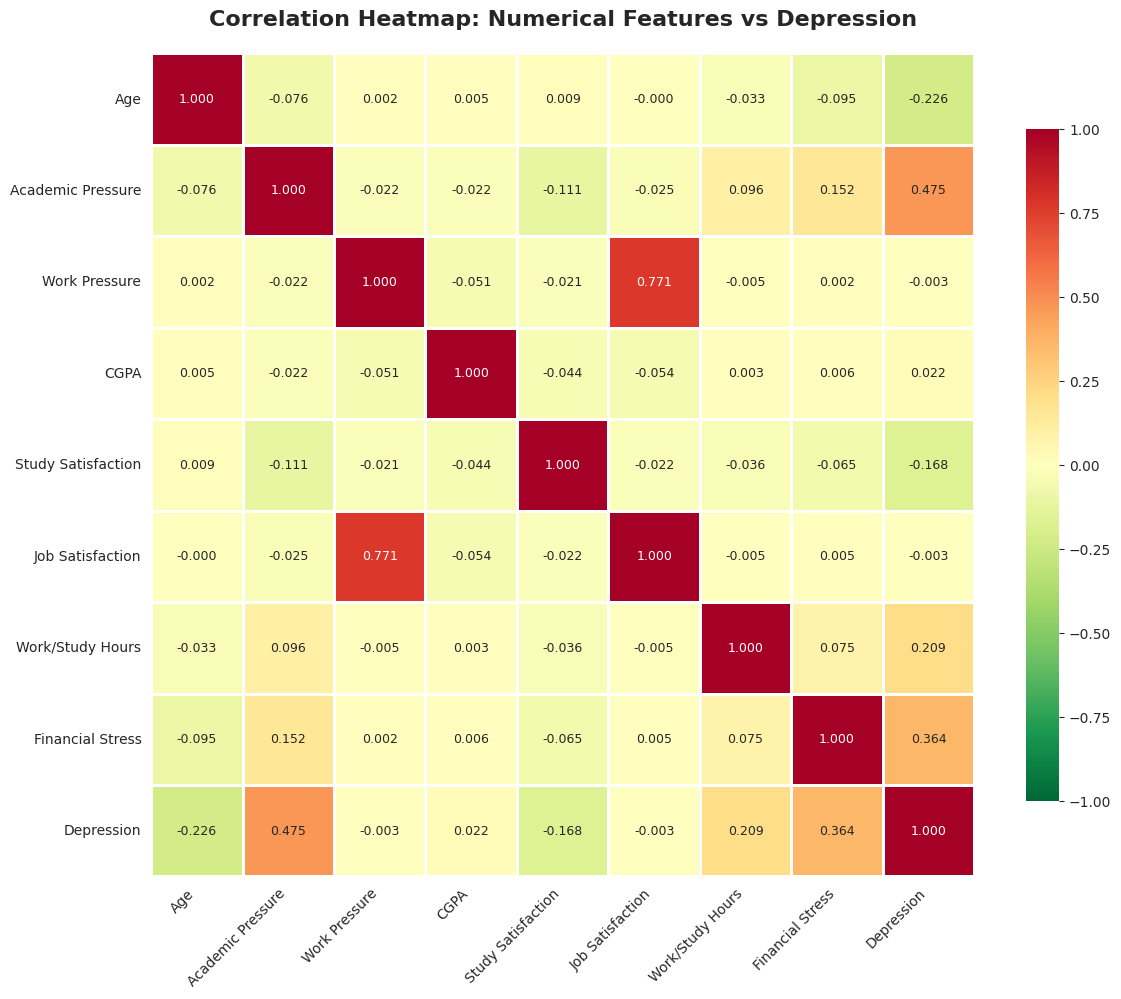

 INTERPRETATION - Top Correlations with Depression:
   • Academic Pressure: 0.475 (strong positive)
   • Financial Stress: 0.364 (moderate positive)
   • Age: -0.226 (moderate negative)
   • Work/Study Hours: 0.209 (moderate positive)
   • Study Satisfaction: -0.168 (weak negative)

   •  KEY INSIGHT: Academic Pressure shows strongest correlation with depression
   • Financial Stress and Work Pressure also show moderate positive correlations
   • CGPA shows very weak correlation, confirming earlier observations


In [21]:
plt.figure(figsize=(12, 10))

numerical_features = ['Age', 'Academic Pressure', 'Work Pressure', 'CGPA',
                      'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours',
                      'Financial Stress', 'Depression']

corr_matrix = df[numerical_features].corr()

sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap='RdYlGn_r', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1, annot_kws={'size': 9})
plt.title('Correlation Heatmap: Numerical Features vs Depression',
          fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(" INTERPRETATION - Top Correlations with Depression:")
dep_corr = corr_matrix['Depression'].drop('Depression').sort_values(key=abs, ascending=False)
for feature, corr_val in dep_corr.head(5).items():
    direction = "positive" if corr_val > 0 else "negative"
    strength = "strong" if abs(corr_val) > 0.4 else "moderate" if abs(corr_val) > 0.2 else "weak"
    print(f"   • {feature}: {corr_val:.3f} ({strength} {direction})")

print("\n   •  KEY INSIGHT: Academic Pressure shows strongest correlation with depression")
print("   • Financial Stress and Work Pressure also show moderate positive correlations")
print("   • CGPA shows very weak correlation, confirming earlier observations")

---

## 5. Dataset Limitations

While this dataset provides valuable insights into student mental health, it is important to acknowledge several limitations that may affect the analysis and interpretation of results.

### Key Limitations:

**1. Self-Reported Data**
- The dataset relies entirely on self-reported survey responses
- Students may under-report or over-report symptoms due to social desirability bias
- Mental health assessments are subjective and may not align with clinical diagnoses
- Memory recall bias may affect accuracy of responses about behaviors and experiences

**2. Cross-Sectional Design**
- Data represents a single point in time (snapshot)
- Cannot establish causal relationships between variables
- Cannot track changes in mental health status over time
- Cannot determine whether academic pressure causes depression or vice versa

**3. Limited Generalizability**
- Dataset may not represent all student populations globally
- Cultural, socioeconomic, and educational system differences may limit applicability
- Sample may not include adequate representation of all demographic groups
- Results may not generalize to students in different geographic regions or educational contexts

**4. Missing Context Variables**
- Important factors are not captured in this dataset:
  - Personal trauma or adverse life events
  - Social support systems and relationships
  - Access to mental health resources
  - Physical health conditions
  - Substance use or medication
  - Previous mental health history before university

**5. Measurement Limitations**
- Depression measured as binary (Yes/No) rather than on a clinical scale
- No information on severity or duration of mental health conditions
- Academic Pressure and Financial Stress use simple scales (1-5) which may not capture nuance
- CGPA ranges are categorical, losing precision of exact grades

**6. Potential Selection Bias**
- Students willing to complete mental health surveys may differ from those who decline
- Students with severe mental health issues may be underrepresented if unable to participate
- Voluntary participation may lead to non-representative sample

**7. Temporal Validity**
- Mental health status can fluctuate significantly over short time periods
- Responses may be influenced by recent events (exams, personal issues)
- Data may not reflect students' typical mental health state

### Implications for Analysis:

Despite these limitations, this dataset remains valuable for:
- Exploratory analysis of relationships between variables
- Identifying patterns and trends in student mental health
- Developing hypotheses for future research
- Building predictive models that can guide screening efforts
- Informing university mental health policies and interventions

**Important Note:** Any predictive models developed from this data should be validated with additional data sources and should not be used as sole diagnostic tools. Clinical assessment by qualified mental health professionals remains essential for diagnosis and treatment decisions.

## 6. Summary of Key Findings

This exploratory data analysis has revealed several important patterns and relationships between student characteristics and mental health outcomes.

### Major Findings:

**1. Prevalence of Mental Health Challenges**
- 58.5% of students (16,336 out of 27,901) report experiencing depression
- 63.3% of students have experienced suicidal thoughts
- These high rates indicate mental health concerns are widespread among university students

**2. Academic Pressure - Strongest Predictor**
- **Strongest correlation with depression** (r = 0.475, p < 0.001)
- Students with depression report significantly higher academic pressure
  - Mean pressure with depression: 3.69 out of 5
  - Mean pressure without depression: 2.36 out of 5
  - Difference: 1.33 points (56% higher)
- Depression rate increases progressively with each level of academic pressure
- **KEY INSIGHT:** Academic pressure appears to be the most significant modifiable factor

**3. Sleep Duration and Mental Health**
- 29.8% of students sleep less than 5 hours per night
- Inadequate sleep (<5 hours) is strongly associated with higher depression rates
- Sleep appears to be an important lifestyle factor affecting mental health

**4. Financial Stress**
- Mean financial stress: 3.14 out of 5 (moderate to high)
- Shows moderate positive correlation with depression
- Depression rates increase with higher financial stress levels
- Students with depression report higher average financial stress

**5. Academic Performance (CGPA) - Weak Association**
- **Surprisingly weak correlation** with depression (r = 0.022)
- Mean CGPA is nearly identical between groups:
  - With depression: 7.68 out of 10
  - Without depression: 7.62 out of 10
- **KEY INSIGHT:** Depression does not necessarily lead to poor academic performance
- High-performing students can also experience mental health challenges

**6. Gender Distribution**
- Sample: 55.7% Male, 44.3% Female
- Depression rates are relatively similar across genders
- Mental health challenges affect both male and female students

**7. Age Distribution**
- Age range: 18-59 years (mean: 25.8 years)
- Dataset includes both traditional and non-traditional students
- Mental health concerns span across age groups

### Implications for Intervention:

**Priority Areas for University Mental Health Support:**

1. **Academic Pressure Management** (Highest Priority)
   - Implement stress management workshops
   - Review academic workload and assessment structures
   - Provide time management and study skills resources
   - Consider modifications to high-pressure academic environments

2. **Sleep Hygiene Education**
   - Promote healthy sleep habits among students
   - Address factors preventing adequate sleep (workload, anxiety, scheduling)
   - Educate on the connection between sleep and mental health

3. **Financial Support Services**
   - Expand financial aid and emergency assistance programs
   - Provide financial literacy and budgeting workshops
   - Address financial stress as a mental health factor

4. **Universal Screening and Early Intervention**
   - Depression affects high-achieving students too
   - Cannot rely solely on academic performance as an indicator
   - Implement comprehensive mental health screening programs
   - Ensure accessible mental health services for all students

### Next Steps for Analysis:

Following this exploratory analysis, the next phase involves:
1. Feature engineering and selection for predictive modeling
2. Development of classification models (Logistic Regression, Decision Trees, Random Forest)
3. Model evaluation using appropriate metrics (accuracy, precision, recall, F1-score)
4. Interpretation of model predictions to identify at-risk students
5. Validation of findings with additional datasets if available

## 7. References

**Dataset:**
- Student Depression Dataset. Kaggle. https://www.kaggle.com/datasets/hopesb/student-depression-dataset

**Libraries and Tools:**
- McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, 56-61.
- Hunter, J. D. (2007). Matplotlib: A 2D Graphics Environment. *Computing in Science & Engineering*, 9(3), 90-95.
- Waskom, M. (2021). Seaborn: Statistical Data Visualization. *Journal of Open Source Software*, 6(60), 3021.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.

**Background Research:**
- American College Health Association. (2023). National College Health Assessment Report.
- Auerbach, R. P., et al. (2018). Mental Disorders Among College Students in the World Health Organization World Mental Health Surveys. *Psychological Medicine*, 48(14), 2955-2970.


